# 디저트 유행은 얼마나 갈까?
### 네이버 검색량으로 본 디저트 수명주기와 출시 타이밍

**질문**: 새로 뜨는 디저트를 지금 출시해도 늦지 않을까? 정규 메뉴로 갈까, 기간 한정으로 갈까?

**데이터**: 네이버 데이터랩 검색어트렌드, 2016.01 ~ 2026.10 주간 데이터, 디저트 키워드 21개 + 기준 키워드 2개(디저트, 떡), 6회 나눠 조회

**방법**
1. 5개 파일을 하나로 합치고, 공통 기준 키워드('디저트')로 서로 비교 가능하게 환산
2. 키워드별로 상승 시작 → 피크 → 반토막까지 걸린 기간 측정
3. 유행형 / 정착형 / 시즌형으로 분류
4. 지금 검색량이 오르는 키워드 찾기

In [1]:
import pandas as pd, numpy as np, glob
import matplotlib.pyplot as plt, matplotlib as mpl
mpl.rcParams.update({'font.family':'Noto Sans CJK JP','axes.spines.top':False,'axes.spines.right':False,
    'axes.edgecolor':'#bdbcb7','axes.labelcolor':'#52514e','xtick.color':'#52514e','ytick.color':'#52514e',
    'axes.grid':True,'grid.color':'#ecebe8','grid.linewidth':0.8,'figure.dpi':120,'axes.titleweight':'bold'})
COLORS=['#2a78d6','#eb6834','#1baf7a','#eda100']

## 1. 데이터 합치기
네이버 데이터랩은 한 번에 5개 키워드까지만 조회되고, 값은 **그 조회 안에서 가장 큰 값을 100으로 둔 상대 비율**이에요.
그래서 조회가 다르면 숫자를 바로 비교할 수 없어요.

해결책: 모든 조회에 **'디저트'를 기준 키워드로 똑같이 넣고**, 각 파일의 '디저트' 값이 1회차와 같아지도록 배율을 맞췄어요.

In [2]:
frames, anchors = [], []
for f in sorted(glob.glob('data/datalab_*.xlsx')):
    x = pd.read_excel(f, header=None)
    names = [str(n).strip() for n in x.iloc[6, 1::2]]
    d = x.iloc[7:].reset_index(drop=True)
    df = pd.DataFrame({n: d[2*i+1].astype(float).values for i, n in enumerate(names)},
                      index=pd.to_datetime(d[0]))
    frames.append(df); anchors.append(df['디저트'])

base = anchors[0]
merged = {}
for df in frames:
    scale = (base / df['디저트']).median()          # 1회차 기준으로 맞추는 배율
    for c in df.columns:
        if c in merged: continue                         # 중복 키워드(디저트, 떡)는 처음 것만 사용
        merged[c] = df[c] * scale
W = pd.DataFrame(merged)
empty = W.columns[W.sum() == 0].tolist()
W = W.loc[:, W.sum() > 0]
# '모찌' 단독은 네이버에서 집계되지 않아(전 기간 0) 연관 검색어를 합쳐 대체 지표를 만든다
W['모찌류(합산)'] = W[['모찌떡', '찹쌀모찌', '과일모찌']].sum(axis=1, min_count=1)
print('주 수:', len(W), '| 키워드:', len(W.columns), '| 검색량 0으로 제외:', empty)
W.to_csv('weekly_normalized.csv', encoding='utf-8-sig')

주 수: 565 | 키워드: 24 | 검색량 0으로 제외: ['모찌']


## 2. 수명주기 측정
뉴스 한 번에 튀는 값에 흔들리지 않도록 **13주(한 분기) 이동평균**으로 추세를 본 뒤,
- **상승 기간**: 피크의 25% 아래에서 출발해 피크까지 걸린 주
- **반감기**: 피크 이후 50% 아래로 떨어지기까지 걸린 주
- **현재 수준**: 최근 13주 평균이 피크의 몇 %인지
- **전년 대비**: 최근 13주를 작년 같은 13주와 비교 (계절 효과 제거)

In [3]:
S = W.rolling(13, center=True, min_periods=7).mean()
rows = []
for c in W.columns:
    s = S[c]; pk = s.idxmax(); pv = s.max()
    pre = s[:pk]; st = pre[pre < 0.25*pv]
    start = st.index[-1] if len(st) else None
    post = s[pk:]; h = post[post < 0.5*pv]
    half = h.index[0] if len(h) else None
    cur = W[c].iloc[-13:].mean(); yago = W[c].iloc[-65:-52].mean()
    rows.append({'키워드': c, '피크': pk.strftime('%Y-%m'),
                 '상승기간(주)': (pk-start).days//7 if start is not None else None,
                 '반감기(주)': (half-pk).days//7 if half is not None else None,
                 '현재수준(피크대비%)': round(cur/pv*100, 1),
                 '전년대비(%)': round((cur/yago-1)*100, 1)})
R = pd.DataFrame(rows).set_index('키워드')

## 3. 유행 유형 분류
- **진행중**: 최근 13주 안에 피크 → 아직 수명주기가 끝나지 않음
- **시즌형**: 매년 같은 달에 오르내림 (월별 패턴이 뚜렷)
- **유행형**: 현재 수준이 피크의 10% 미만으로 꺼짐
- **정착형**: 피크의 25% 이상을 유지
- **관망형**: 그 사이

In [4]:
trend = W.rolling(52, center=True, min_periods=26).mean()
season = (W / trend).groupby(W.index.month).mean()
R['계절폭'] = (season.max() / season.min()).round(2)
R['계절피크(월)'] = season.idxmax()

recent_peak = {c: S[c].idxmax() >= W.index[-13] for c in W.columns}
def kind(r):
    if r.name in ('디저트', '떡'): return '기준'
    if recent_peak[r.name]: return '진행중'
    if r['계절폭'] >= 2.5 and r['현재수준(피크대비%)'] >= 10: return '시즌형'
    if r['현재수준(피크대비%)'] < 10: return '유행형'
    if r['현재수준(피크대비%)'] >= 25: return '정착형'
    return '관망형'
R['유형'] = R.apply(kind, axis=1)
R.sort_values(['유형', '상승기간(주)'])

,피크,상승기간(주),반감기(주),현재수준(피크대비%),전년대비(%),계절폭,계절피크(월),유형
키워드,,,,,,,,
마라탕,2019-06,16.0,12.0,18.6,-19.8,1.55,7,관망형
요거트 아이스크림,2024-08,27.0,12.0,12.2,-58.8,1.92,7,관망형
말차,2025-09,31.0,19.0,19.5,-80.1,1.17,8,관망형
디저트,2023-04,NaN,NaN,68.4,-7.0,1.09,3,기준
떡,2021-01,NaN,229.0,45.8,-15.5,1.47,9,기준
쑥,2020-04,12.0,10.0,11.2,-29.3,6.76,4,시즌형
딸기모찌,2025-01,16.0,12.0,28.2,-17.3,3.28,1,시즌형
약과,2023-02,65.0,19.0,16.1,-24.9,2.51,9,시즌형
찹쌀떡,2020-12,NaN,12.0,50.3,22.8,2.57,11,시즌형


## 4. 핵심 발견 ① 급하게 뜬 디저트는 급하게 진다
피크 시점을 0주로 맞춰 겹쳐 보면, 유행형은 몇 달 만에 올라갔다 그만큼 빨리 내려오고, 정착형은 몇 년에 걸쳐 천천히 오르고 천천히 내려와요.

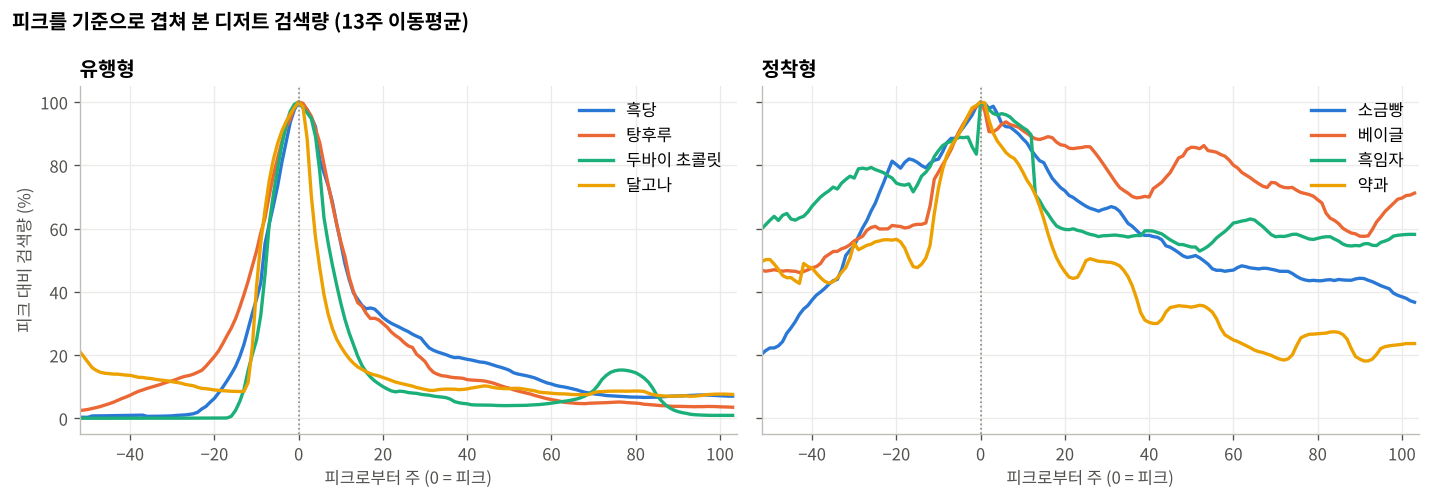

In [5]:
def aligned(c, before=52, after=104):
    s = S[c]; i = s.index.get_loc(s.idxmax())
    seg = s.iloc[max(0, i-before): i+after] / s.max() * 100
    return pd.Series(seg.values, index=np.arange(max(0, i-before)-i, max(0, i-before)-i+len(seg)))

groups = {'유행형': ['흑당', '탕후루', '두바이 초콜릿', '달고나'],
          '정착형': ['소금빵', '베이글', '흑임자', '약과']}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (g, ks) in zip(axes, groups.items()):
    for k, col in zip(ks, COLORS):
        a = aligned(k); ax.plot(a.index, a.values, color=col, lw=2, label=k)
    ax.axvline(0, color='#8a8984', lw=1, ls=':')
    ax.set_title(g, loc='left'); ax.set_xlabel('피크로부터 주 (0 = 피크)')
    ax.set_xlim(-52, 104); ax.legend(frameon=False, loc='upper right')
axes[0].set_ylabel('피크 대비 검색량 (%)')
fig.suptitle('피크를 기준으로 겹쳐 본 디저트 검색량 (13주 이동평균)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.savefig('fig1_lifecycle.png', bbox_inches='tight'); plt.show()

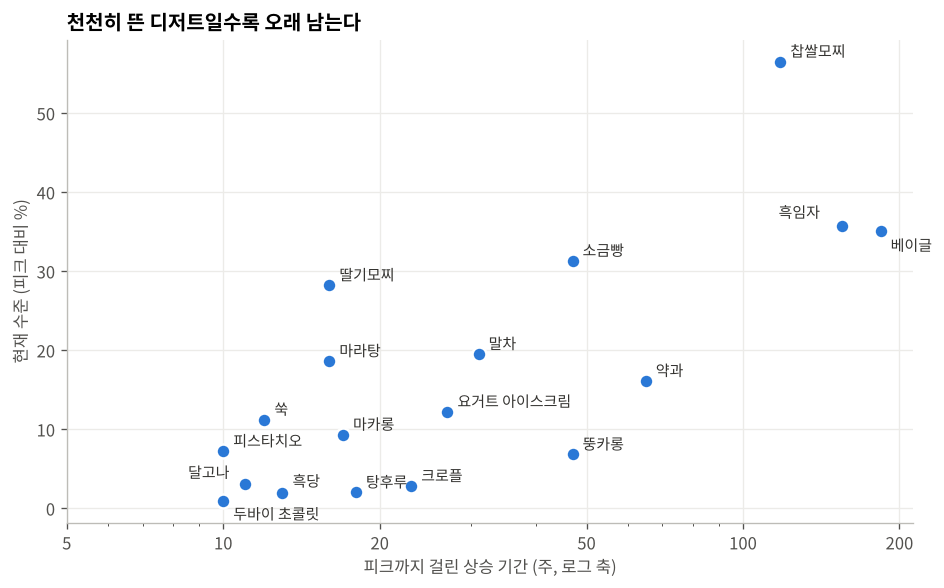

20주 이내 급상승 9개: 현재 수준 중앙값 7.2% / 반감기 중앙값 10주
40주 이상 완만 상승 6개: 현재 수준 중앙값 33.2% / 반감기 중앙값 48주


순위 상관(상승기간 vs 현재수준): 0.68


In [6]:
P = R[R['상승기간(주)'].notna() & ~R['유형'].isin(['기준', '진행중'])]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(P['상승기간(주)'], P['현재수준(피크대비%)'], s=70, color=COLORS[0], edgecolor='white', lw=1.5, zorder=3)
OFF = {'두바이 초콜릿': (6, -11), '흑당': (6, 4), '흑임자': (-38, 5), '베이글': (6, -12), '달고나': (-34, 4)}
for k, r in P.iterrows():
    ax.annotate(k, (r['상승기간(주)'], r['현재수준(피크대비%)']), xytext=OFF.get(k, (6, 3)), textcoords='offset points', fontsize=9, color='#33322f')
ax.set_xscale('log'); ax.set_xticks([5, 10, 20, 50, 100, 200]); ax.set_xticklabels(['5', '10', '20', '50', '100', '200'])
ax.set_xlabel('피크까지 걸린 상승 기간 (주, 로그 축)'); ax.set_ylabel('현재 수준 (피크 대비 %)')
ax.set_title('천천히 뜬 디저트일수록 오래 남는다', loc='left')
plt.tight_layout(); plt.savefig('fig2_rise_vs_survival.png', bbox_inches='tight'); plt.show()
fast = P[P['상승기간(주)'] <= 20]; slow = P[P['상승기간(주)'] >= 40]
print(f"20주 이내 급상승 {len(fast)}개: 현재 수준 중앙값 {fast['현재수준(피크대비%)'].median():.1f}% / 반감기 중앙값 {fast['반감기(주)'].median():.0f}주")
print(f"40주 이상 완만 상승 {len(slow)}개: 현재 수준 중앙값 {slow['현재수준(피크대비%)'].median():.1f}% / 반감기 중앙값 {slow['반감기(주)'].median():.0f}주")
print('순위 상관(상승기간 vs 현재수준):', round(P['상승기간(주)'].corr(P['현재수준(피크대비%)'], method='spearman'), 2))

## 5. 핵심 발견 ② 시즌형 디저트는 출시 달이 정해져 있다
추세를 걷어내고 월별 평균을 보면, 몇몇 디저트는 매년 같은 달에 검색이 몰려요. (1.0 = 연평균)

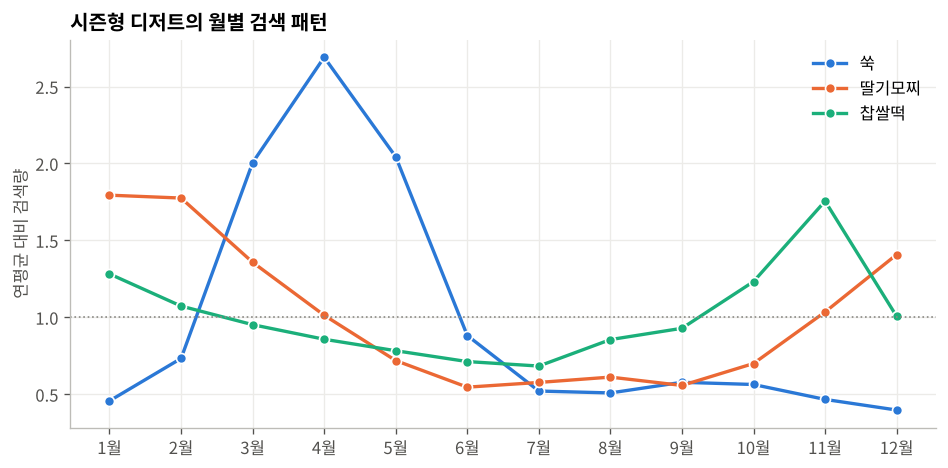

In [7]:
ks = [k for k in ['쑥', '딸기모찌', '찹쌀떡'] if k in season.columns]
fig, ax = plt.subplots(figsize=(8, 4))
for k, col in zip(ks, COLORS):
    ax.plot(season.index, season[k], color=col, lw=2, marker='o', ms=6, mec='white', label=k)
ax.axhline(1, color='#8a8984', lw=1, ls=':')
ax.set_xticks(range(1, 13)); ax.set_xticklabels([f'{m}월' for m in range(1, 13)])
ax.set_ylabel('연평균 대비 검색량'); ax.legend(frameon=False)
ax.set_title('시즌형 디저트의 월별 검색 패턴', loc='left')
plt.tight_layout(); plt.savefig('fig3_season.png', bbox_inches='tight'); plt.show()

## 6. 지금 오르는 키워드
최근 13주를 작년 같은 시기와 비교했어요. 같은 계절끼리 비교해서 시즌 효과는 빠져 있어요.

In [8]:
R[~R['유형'].isin(['기준'])].sort_values('전년대비(%)', ascending=False)[['유형', '피크', '현재수준(피크대비%)', '전년대비(%)']]

,유형,피크,현재수준(피크대비%),전년대비(%)
키워드,,,,
과일모찌,진행중,2026-10,77.2,186.9
모찌류(합산),진행중,2026-10,77.5,166.8
찹쌀모찌,정착형,2021-12,56.5,87.3
찹쌀떡,시즌형,2020-12,50.3,22.8
모찌떡,정착형,2018-01,32.9,1.7
딸기모찌,시즌형,2025-01,28.2,-17.3
마라탕,관망형,2019-06,18.6,-19.8
흑당,유행형,2019-07,1.9,-20.0
뚱카롱,유행형,2019-02,6.8,-22.3


## 7. 사례 분석: 과일모찌, 지금 출시해도 될까?
과일모찌는 2026년 10월 현재 **역대 최고 검색량**을 기록 중이에요. 앞에서 찾은 규칙으로 판단해 봤어요.
비교 방법: 피크 1년 전 검색량이 피크의 몇 %였는지 (유행형은 바닥에서 갑자기, 정착형은 이미 꽤 높은 곳에서 출발)

피크 대비 % (중앙값)


,유행형,정착형,과일모찌
피크 52주 전,1.4,48.1,26.7
피크 26주 전,5.9,62.9,20.9
피크 13주 전,16.2,69.8,37.5


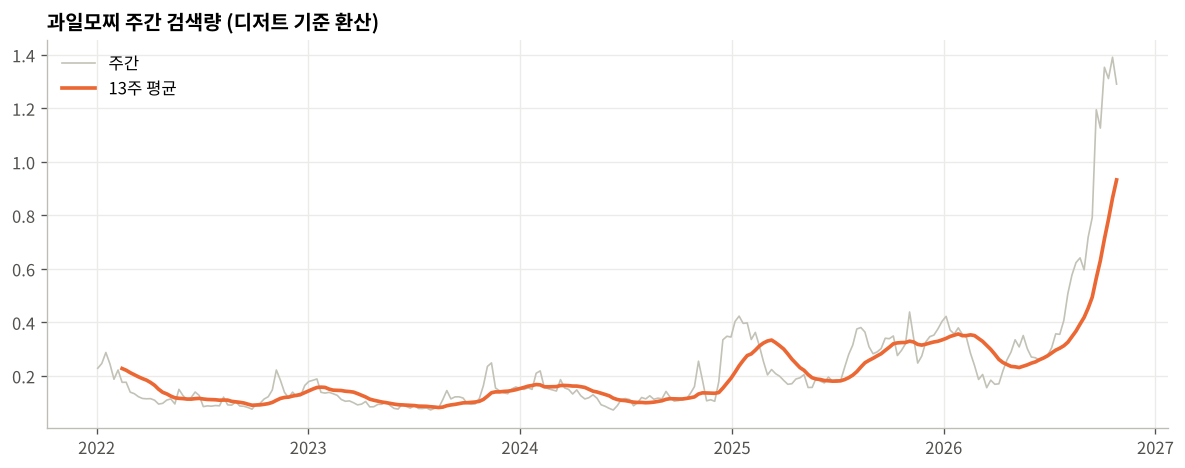

과일모찌 최근 13주 전년 대비: 186.9 %
찹쌀떡 최근 13주 전년 대비: 22.8 %


In [9]:
def pre_level(c, weeks):
    s = S[c].dropna(); pk = s.idxmax(); i = s.index.get_loc(pk)
    return s.iloc[i-weeks] / s.max() * 100 if i >= weeks else np.nan
cmp = pd.DataFrame({g: [np.nanmedian([pre_level(k, w) for k in ks]) for w in (52, 26, 13)] for g, ks in groups.items()},
                   index=['피크 52주 전', '피크 26주 전', '피크 13주 전'])
cmp['과일모찌'] = [pre_level('과일모찌', w) for w in (52, 26, 13)]
print('피크 대비 % (중앙값)'); display(cmp.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
s = W['과일모찌'].loc['2022-01-01':]
ax.plot(s.index, s.values, color='#c3c2b7', lw=1, label='주간')
ax.plot(s.index, s.rolling(13, min_periods=7).mean(), color=COLORS[1], lw=2.2, label='13주 평균')
ax.set_title('과일모찌 주간 검색량 (디저트 기준 환산)', loc='left'); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.savefig('fig4_fruit_mochi.png', bbox_inches='tight'); plt.show()
print('과일모찌 최근 13주 전년 대비:', R.loc['과일모찌', '전년대비(%)'], '%')
print('찹쌀떡 최근 13주 전년 대비:', R.loc['찹쌀떡', '전년대비(%)'], '%')

## 8. 기획 제안 (데이터 해석은 아래 결과를 보고 작성)
- **유행형 신호** (짧은 기간에 급상승): 기간 한정 메뉴로, 빠르게 출시하고 빠르게 빠진다
- **정착형 신호** (1년 이상 꾸준히 상승): 정규 메뉴와 라인업 확장으로 간다
- **시즌형**: 피크 달 1~2개월 전에 출시 일정을 고정한다

**한계**: 검색량은 관심도이지 매출이 아니다 / 키워드 표기에 따라 결과가 달라진다 / 표본 19개로 일반화에는 한계가 있다